# AIMLZG557 – Artificial and Computational Intelligence
## Assignment 2 – Question 1 (Group): Mini-chess with Minimax

**Group:** 70

| Name | BITS ID |
|---|---|
| LAKSHYA KANCHAN | 2025AG05062 |
| SHREYANSH SHARMA | 2025AG05772 |
| VINAY PRATAP SINGH BHADAURIA | 2025AG05689 |
| ABHISHEK GHOSH | 2025AG05076 |
| SATHIYALATHASHRI N | 2025AG05239 |

## 1. Problem statement and board

> *Simulate the working of chess with the below sample smaller game board. A player with any piece/coin standing where its opponent sacrifices all the piece/coin is a win for the first player.*
> *Soldier/Pawn (S) can move only one straight step ahead. Only if opponent coins are available, it can move diagonally one step forward to attack the opponent coin.*
> *Horses/Knight (H) can move either forward/backward in L-shaped strides covering exactly 3 tiles. It is the only piece that can jump over other coins.*
> *Choose and justify a static evaluation function (no machine learning), explain it with a sample game state. One player must be a human (dynamic input), the other is simulated by the program, using the **Minimax** algorithm.*

The board in the assignment image is 3 × 3:

| | a | b | c |
|---|---|---|---|
| **3** | White S | White H | – |
| **2** | – | – | – |
| **1** | – | Black S | Black H |

* White (outlined pieces) starts on rank 3 and moves down. Black (filled pieces) starts on rank 1 and moves up.
* By default the human plays White and moves first (chess convention), and the computer plays Black. `HUMAN_SIDE` changes this.

In [ ]:
from collections import Counter, namedtuple
import time

ROWS, COLS = 3, 3          # board from the assignment image
FILES = "abc"              # files a..c left to right; ranks 1..3 bottom to top

# Interpretation flags (see the rules table in the notebook)
ALLOW_SIDEWAYS_L = True    # knight may also move (1 rank, 2 files); False = only (2 ranks, 1 file)
NO_MOVE_RULE = "pass"      # side with no legal move: "pass" | "loss" | "draw"
MAX_PLIES = 40             # move cap -> draw
REPETITION_LIMIT = 3       # same position (board + side to move) seen 3 times -> draw

# Evaluation weights (hand-designed, no machine learning)
PIECE_VALUE = {"S": 10, "H": 30}
W_MOBILITY = 1
W_ADVANCE = 2
W_THREAT = 3
SAFETY_FRACTION = 0.5      # penalty = 50% of a hanging piece's value
WIN_SCORE = 1000


In [ ]:
# board: tuple of ROWS*COLS cells, index = row*COLS + col, row 0 = rank 3 (top).
# Each cell is None or a 2-char piece code: colour ('W'/'B') + kind ('S'/'H').
State = namedtuple("State", "board turn")


def other(color):
    return "B" if color == "W" else "W"


def sq_name(i):
    r, c = divmod(i, COLS)
    return f"{FILES[c]}{ROWS - r}"


def sq_index(name):
    name = name.strip().lower()
    if len(name) != 2 or name[0] not in FILES or not name[1].isdigit():
        raise ValueError(f"bad square '{name}'")
    c, rank = FILES.index(name[0]), int(name[1])
    if not 1 <= rank <= ROWS:
        raise ValueError(f"bad square '{name}'")
    return (ROWS - rank) * COLS + c


def make_state(pieces, turn="W"):
    """pieces: dict like {'a3': 'WS', 'b3': 'WH'}"""
    board = [None] * (ROWS * COLS)
    for sq, p in pieces.items():
        board[sq_index(sq)] = p
    return State(tuple(board), turn)


START = make_state({"a3": "WS", "b3": "WH", "b1": "BS", "c1": "BH"}, "W")


def forward(color):
    return 1 if color == "W" else -1    # White starts on top and moves down


def render(state):
    lines = ["     " + "    ".join(FILES)]
    for r in range(ROWS):
        cells = [state.board[r * COLS + c] or " . " for c in range(COLS)]
        cells = [x if x == " . " else f"{x[0]}-{x[1]}" for x in cells]
        lines.append(f"{ROWS - r} | " + "  ".join(cells) + " |")
    lines.append(f"to move: {'White' if state.turn == 'W' else 'Black'}")
    return "\n".join(lines)


     a    b    c
3 | W-S  W-H   .  |
2 |  .    .    .  |
1 |  .   B-S  B-H |
to move: White


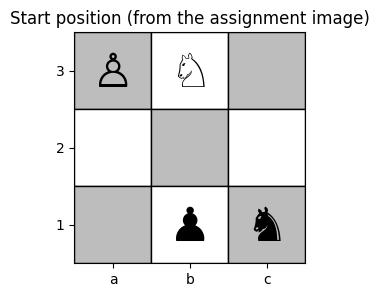

In [3]:
import matplotlib.pyplot as plt

GLYPH = {"WS": "\u2659", "WH": "\u2658", "BS": "\u265F", "BH": "\u265E"}

def draw_board(state, title=""):
    fig, ax = plt.subplots(figsize=(3, 3))
    for r in range(ROWS):
        for c in range(COLS):
            shade = "#bdbdbd" if (r + c) % 2 == 0 else "#ffffff"
            ax.add_patch(plt.Rectangle((c, ROWS - 1 - r), 1, 1, facecolor=shade, edgecolor="black"))
            p = state.board[r * COLS + c]
            if p:
                ax.text(c + 0.5, ROWS - 1 - r + 0.45, GLYPH[p], fontsize=34, ha="center", va="center",
                        family="DejaVu Sans")
    ax.set_xticks([i + 0.5 for i in range(COLS)], list(FILES))
    ax.set_yticks([i + 0.5 for i in range(ROWS)], [str(i + 1) for i in range(ROWS)])
    ax.set_xlim(0, COLS); ax.set_ylim(0, ROWS); ax.set_aspect("equal")
    ax.set_title(title)
    plt.show()

print(render(START))
draw_board(START, "Start position (from the assignment image)")

## 2. Rules and interpretation decisions

The wording leaves some room for interpretation. Every choice below is a flag in the config cell above.

| # | Rule | Our interpretation | Why |
|---|---|---|---|
| D1 | Pawn straight move | One step forward, only onto an empty square | "only one straight step ahead". A straight step does not capture, as in chess. |
| D2 | Pawn diagonal | One step diagonally forward, only to capture an enemy piece | "Only if opponent coins are available … diagonally one step forward to attack" |
| D3 | Pawn double step / en passant | Not allowed | "only one" step |
| D4 | Knight geometry | Standard L: (±2 ranks, ±1 file) **and** (±1 rank, ±2 files). `ALLOW_SIDEWAYS_L = True` | An L "covering exactly 3 tiles" is the chess knight's 2+1 stride. Every L changes the rank, so each one is "forward or backward"; the phrase contrasts the knight with the forward-only pawn. Set the flag to `False` for the strict reading (2 ranks + 1 file only). |
| D5 | Knight jumping | Squares in between are ignored. It may land on an empty or enemy square. | "the only piece that can jump over other coins" |
| D6 | Friendly squares | No piece may land on a friendly piece | Chess rule |
| D7 | Win | The side that removes all opposing pieces wins | Docx win condition |
| D8 | No legal move | `NO_MOVE_RULE = "pass"`: the side passes. If neither side can move, the game is a draw. Other options: `"loss"`, `"draw"` | The docx gives a single way to win (eliminate all pieces), so being stuck is not a loss. Pawns get stuck easily on a 3×3 board, so a pass keeps the game alive while a knight can still move. |
| D9 | Draws | `MAX_PLIES = 40` move cap, and threefold repetition (same board and side to move) | Two knights can shuffle forever, so every game must end |
| D10 | Promotion | None. A pawn on the last rank stays there and cannot move. | Not mentioned in the docx |
| D11 | Check / king | None | There is no king on this board |

## 3. State representation

* `State(board, turn)` is an immutable named tuple, so it is hashable and can be counted for repetition detection.
* `board` is a tuple of 9 cells, with index `row*3 + col`, where row 0 is rank 3 (the top). A cell is `None` or a 2-character code: colour `W`/`B` + kind `S`/`H`.
* `turn` is `'W'` or `'B'`. A move is a pair `(from_index, to_index)`. `None` is a pass.
* `game_result(state, ply, history)` applies the win, repetition, move-cap and no-move rules.

## 4. Move generation

In [4]:
def knight_deltas():
    d = [(2, 1), (2, -1), (-2, 1), (-2, -1)]
    if ALLOW_SIDEWAYS_L:
        d += [(1, 2), (1, -2), (-1, 2), (-1, -2)]
    return d


def on_board(r, c):
    return 0 <= r < ROWS and 0 <= c < COLS


def piece_targets(board, i):
    """Legal destination squares for the piece on square i."""
    color, kind = board[i]
    r, c = divmod(i, COLS)
    out = []
    if kind == "S":
        r2 = r + forward(color)
        if on_board(r2, c) and board[r2 * COLS + c] is None:
            out.append(r2 * COLS + c)                     # straight step: empty only
        for dc in (-1, 1):
            if on_board(r2, c + dc):
                t = board[r2 * COLS + c + dc]
                if t is not None and t[0] != color:       # diagonal: capture only
                    out.append(r2 * COLS + c + dc)
    else:
        for dr, dc in knight_deltas():                     # jumps: squares between are ignored
            if on_board(r + dr, c + dc):
                t = board[(r + dr) * COLS + c + dc]
                if t is None or t[0] != color:
                    out.append((r + dr) * COLS + c + dc)
    return out


def attacked_squares(board, i):
    """Squares the piece on i could capture on, if an enemy stood there."""
    color, kind = board[i]
    r, c = divmod(i, COLS)
    if kind == "S":
        r2 = r + forward(color)
        return [r2 * COLS + c + dc for dc in (-1, 1) if on_board(r2, c + dc)]
    return [(r + dr) * COLS + c + dc for dr, dc in knight_deltas() if on_board(r + dr, c + dc)]


def pieces_of(board, color):
    return [i for i, p in enumerate(board) if p and p[0] == color]


def legal_moves(state):
    """List of (from, to) moves. Captures first (same order for every search)."""
    board, moves = state.board, []
    for i in pieces_of(board, state.turn):
        for j in piece_targets(board, i):
            moves.append((i, j))
    moves.sort(key=lambda m: (board[m[1]] is None, m))
    return moves


def apply_move(state, move):
    """move = (from, to) or None for a pass."""
    if move is None:
        return State(state.board, other(state.turn))
    i, j = move
    b = list(state.board)
    b[j], b[i] = b[i], None
    return State(tuple(b), other(state.turn))


def move_name(state, move):
    if move is None:
        return "pass"
    i, j = move
    cap = "x" if state.board[j] else "-"
    return f"{state.board[i][1]} {sq_name(i)}{cap}{sq_name(j)}"


def winner(state):
    """Colour that has eliminated every opposing piece, else None."""
    w, b = pieces_of(state.board, "W"), pieces_of(state.board, "B")
    if not b and w:
        return "W"
    if not w and b:
        return "B"
    return None


def game_result(state, ply, history):
    """'W' / 'B' / 'draw' if the game is over at this node, else None.
    ply = plies played so far; history = Counter of positions seen (incl. this one)."""
    w = winner(state)
    if w:
        return w
    if history.get(state, 0) >= REPETITION_LIMIT or ply >= MAX_PLIES:
        return "draw"
    if not legal_moves(state):
        if NO_MOVE_RULE == "loss":
            return other(state.turn)
        if NO_MOVE_RULE == "draw":
            return "draw"
        if not legal_moves(State(state.board, other(state.turn))):
            return "draw"                                   # pass rule: nobody can move
    return None


def search_moves(state):
    """Moves to search: legal moves, or [None] (a pass) when stuck under the pass rule."""
    return legal_moves(state) or [None]


In [5]:
# Legal moves from the start position, checked with asserts
start_moves = sorted(move_name(START, m) for m in legal_moves(START))
print("White's legal moves at the start:", start_moves)
assert start_moves == ["H b3-a1", "H b3xc1", "S a3-a2"]
# a3 pawn: a2 is empty (straight step OK); b2 is empty (no diagonal without a capture)
# b3 knight: a1 empty, c1 holds the Black knight (capture)

black_view = State(START.board, "B")
black_moves = sorted(move_name(black_view, m) for m in legal_moves(black_view))
print("Black's legal moves if Black were to move:", black_moves)
assert black_moves == ["H c1-a2", "H c1xb3", "S b1-b2"]

# a few rule checks
s = make_state({"b3": "WS", "b2": "BS"})
assert piece_targets(s.board, sq_index("b3")) == []                    # pawn cannot capture straight
s = make_state({"a1": "WH", "a2": "WS", "b2": "BS", "b1": "BS"})
assert sq_index("b3") in piece_targets(s.board, sq_index("a1"))        # knight jumps over pieces
s = make_state({"a1": "WH", "b3": "WS", "c2": "WS"})
assert piece_targets(s.board, sq_index("a1")) == []                    # never onto a friendly piece
print("All move-generation asserts passed.")

White's legal moves at the start: ['H b3-a1', 'H b3xc1', 'S a3-a2']
Black's legal moves if Black were to move: ['H c1-a2', 'H c1xb3', 'S b1-b2']
All move-generation asserts passed.


## 5. Static evaluation function (hand-designed, no machine learning)

The score is from White's point of view: positive is good for White, negative is good for Black. Each term is computed for both sides and the result is White − Black, so the function is symmetric (a colour-mirrored position gets the negated score; pytest checks this).

$$E(s) = \underbrace{\text{Material}}_{S=10,\;H=30} + \underbrace{1\cdot\text{Mobility}}_{\#\text{legal moves}} + \underbrace{2\cdot\text{Advancement}}_{\text{pawn ranks gained}} + \underbrace{3\cdot\text{Threats}}_{\#\text{enemy pieces attacked}} \;-\; \underbrace{0.5\cdot\text{value of hanging pieces}}_{\text{Safety}}$$

| Term | Weight | Justification |
|---|---|---|
| Material | S = 10, H = 30 | The game is won by removing every enemy piece, so material comes first. The 1 : 3 ratio follows chess. The knight is worth more here too: it moves both ways, jumps, and is never stuck, whereas a pawn on the last rank is frozen. |
| Mobility | 1 per legal move | More options means less risk of being forced to pass, and more chances to attack. The weight is low, so mobility can never outweigh a piece (max mobility on 3×3 is about 6). |
| Advancement | 2 per rank a pawn has gained | A pawn can only capture forward, so advancing brings it toward enemy pieces. The weight is small because a pawn on the last rank is stuck. |
| Threats | 3 per enemy piece we attack | Attacking pieces turns into material at the next move. The weight is below a pawn's value so the search still prefers real captures. |
| Safety | −50% of the value of each own piece that is attacked and not defended | A hanging piece is likely to be lost. We use half its value, because it is only lost if the opponent actually takes it. |
| Terminal | ±(1000 − ply) | A win or loss outranks any heuristic. Subtracting the ply makes the engine prefer faster wins and slower losses. A draw scores 0. |

The weights are small integers chosen by reasoning about the game, not fitted to data. Section 9 compares this function with a material-only baseline.

In [6]:
def eval_terms(state):
    """Each evaluation term for White and Black. Positive total = good for White."""
    board = state.board
    terms = {}
    attacks = {col: Counter(sq for i in pieces_of(board, col) for sq in attacked_squares(board, i))
               for col in "WB"}
    for col in "WB":
        mine = pieces_of(board, col)
        enemy = other(col)
        material = sum(PIECE_VALUE[board[i][1]] for i in mine)
        mobility = W_MOBILITY * sum(len(piece_targets(board, i)) for i in mine)
        advance = 0
        for i in mine:
            if board[i][1] == "S":
                r = i // COLS
                advance += W_ADVANCE * (r if col == "W" else ROWS - 1 - r)
        threats = W_THREAT * sum(1 for j in pieces_of(board, enemy) if attacks[col][j])
        safety = -sum(SAFETY_FRACTION * PIECE_VALUE[board[i][1]]
                      for i in mine if attacks[enemy][i] and not attacks[col][i])
        terms[col] = {"material": material, "mobility": mobility, "advancement": advance,
                      "threats": threats, "safety": safety}
    return terms


def evaluate(state):
    t = eval_terms(state)
    return sum(t["W"].values()) - sum(t["B"].values())


def eval_table(state):
    t = eval_terms(state)
    rows = [(k, t["W"][k], t["B"][k], t["W"][k] - t["B"][k]) for k in t["W"]]
    total = sum(r[3] for r in rows)
    out = [f"{'term':<12}{'White':>8}{'Black':>8}{'W - B':>8}"]
    out += [f"{k:<12}{w:>8g}{b:>8g}{d:>8g}" for k, w, b, d in rows]
    out.append(f"{'TOTAL':<12}{'':>8}{'':>8}{total:>8g}")
    return "\n".join(out)


### Worked example on a sample game state

Sample state (White to move):

| | a | b | c |
|---|---|---|---|
| **3** | – | Black H | – |
| **2** | White S | – | Black S |
| **1** | White H | – | – |

Attack map (a pawn attacks its two forward diagonals; a knight attacks its L-squares):
* White S a2 → attacks b1 (empty). Its straight step to a1 is blocked by its own knight, so it has 0 moves.
* White H a1 → b3 (Black H) and c2 (Black S): 2 moves, 2 enemy pieces attacked.
* Black S c2 (moves up) → c3 straight (empty): 1 move. It attacks b3, which defends its own knight.
* Black H b3 → a1 (White H, capture) and c1: 2 moves. It attacks a1.

| Term | White | Black | W − B | How |
|---|---|---|---|---|
| Material | 10 + 30 = 40 | 10 + 30 = 40 | 0 | equal pieces |
| Mobility | 0 + 2 = 2 | 1 + 2 = 3 | −1 | legal-move counts above |
| Advancement | 2·1 = 2 | 2·1 = 2 | 0 | each pawn has advanced one rank |
| Threats | 3·2 = 6 | 3·1 = 3 | +3 | W attacks BH and BS; B attacks WH |
| Safety | −0.5·30 = −15 | −0.5·10 = −5 | −10 | WH a1 attacked by BH and undefended; BS c2 attacked by WH and undefended; BH b3 attacked but defended by BS, so no penalty |
| Total | | | −8 | |

The static score says White is slightly worse, mainly because the White knight hangs. Static evaluation does not look ahead, though: it is White's move, and a 1-ply search finds H a1xb3 (+13; computed in Section 6). This is why the evaluation is used at the leaves of a Minimax search and not on its own.

     a    b    c
3 |  .   B-H   .  |
2 | W-S   .   B-S |
1 | W-H   .    .  |
to move: White

term           White   Black   W - B
material          40      40       0
mobility           2       3      -1
advancement        2       2       0
threats            6       3       3
safety           -15      -5     -10
TOTAL                             -8


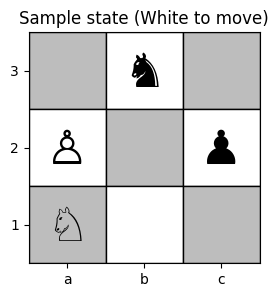

In [7]:
sample = make_state({"a2": "WS", "a1": "WH", "c2": "BS", "b3": "BH"}, "W")
print(render(sample)); print()
print(eval_table(sample))
assert evaluate(sample) == -8
draw_board(sample, "Sample state (White to move)")

## 6. Minimax, and alpha-beta pruning

* `minimax(state, depth)`: plain Minimax as required by the assignment. White maximises, Black minimises. At depth 0 it returns the static evaluation. A finished game returns a terminal score.
* The search follows the game's own end rules: the position history is carried down the tree, so repetition draws, the move cap and passes are scored the same way as in a real game.
* `alphabeta(...)` gives the same result while pruning branches that cannot change the decision. Both use the same move order (captures first) and only replace the best move on a strict improvement, so they always return the same move. pytest checks this on many random positions.
* The computer player uses plain `minimax` by default (`ALGORITHM = "minimax"`). Alpha-beta is used here for comparison.

In [8]:
class Stats:
    def __init__(self):
        self.nodes = 0


def _terminal_score(result, depth_from_root):
    if result == "draw":
        return 0
    s = WIN_SCORE - depth_from_root          # prefer faster wins, slower losses
    return s if result == "W" else -s


def minimax(state, depth, ply=0, history=None, stats=None, _d=0, eval_fn=None):
    """Plain Minimax. Returns (value, best_move); value is from White's view.
    White maximises, Black minimises."""
    history = Counter({state: 1}) if history is None else history
    stats = stats or Stats()
    stats.nodes += 1
    result = game_result(state, ply, history)
    if result:
        return _terminal_score(result, _d), None
    if depth == 0:
        return (eval_fn or evaluate)(state), None
    maximizing = state.turn == "W"
    best_val, best_move = (float("-inf") if maximizing else float("inf")), None
    for m in search_moves(state):
        child = apply_move(state, m)
        history[child] += 1
        val, _ = minimax(child, depth - 1, ply + 1, history, stats, _d + 1, eval_fn)
        history[child] -= 1
        if (maximizing and val > best_val) or (not maximizing and val < best_val):
            best_val, best_move = val, m
    return best_val, best_move


def alphabeta(state, depth, ply=0, history=None, stats=None, alpha=float("-inf"),
              beta=float("inf"), _d=0, eval_fn=None):
    """Minimax with alpha-beta pruning. Same value and move as minimax, fewer nodes."""
    history = Counter({state: 1}) if history is None else history
    stats = stats or Stats()
    stats.nodes += 1
    result = game_result(state, ply, history)
    if result:
        return _terminal_score(result, _d), None
    if depth == 0:
        return (eval_fn or evaluate)(state), None
    maximizing = state.turn == "W"
    best_val, best_move = (float("-inf") if maximizing else float("inf")), None
    for m in search_moves(state):
        child = apply_move(state, m)
        history[child] += 1
        val, _ = alphabeta(child, depth - 1, ply + 1, history, stats, alpha, beta, _d + 1,
                           eval_fn)
        history[child] -= 1
        if maximizing:
            if val > best_val:
                best_val, best_move = val, m
            alpha = max(alpha, val)
        else:
            if val < best_val:
                best_val, best_move = val, m
            beta = min(beta, val)
        if alpha >= beta:
            break
    return best_val, best_move


def choose_move(state, depth, ply=0, history=None, algorithm="minimax", eval_fn=None):
    stats = Stats()
    t0 = time.perf_counter()
    fn = minimax if algorithm == "minimax" else alphabeta
    val, move = fn(state, depth, ply, Counter(history or {state: 1}), stats, eval_fn=eval_fn)
    return move, val, stats.nodes, time.perf_counter() - t0


In [9]:
print(f"{'depth':>5} | {'minimax move':>12} {'value':>6} {'nodes':>7} | {'alpha-beta move':>15} {'value':>6} {'nodes':>6} | pruned")
for d in range(1, 9):
    m1, v1, n1, _ = choose_move(START, d, algorithm="minimax")
    m2, v2, n2, _ = choose_move(START, d, algorithm="alphabeta")
    assert (m1, v1) == (m2, v2)
    print(f"{d:>5} | {move_name(START, m1):>12} {v1:>6g} {n1:>7} | {move_name(START, m2):>15} {v2:>6g} {n2:>6} | {100 * (1 - n2 / n1):5.1f}%")

depth | minimax move  value   nodes | alpha-beta move  value  nodes | pruned
    1 |      H b3xc1     32       4 |         H b3xc1     32      4 |   0.0%
    2 |      H b3xc1     30      12 |         H b3xc1     30      7 |  41.7%
    3 |      H b3xc1    997      34 |         H b3xc1    997     17 |  50.0%
    4 |      H b3xc1    997      86 |         H b3xc1    997     26 |  69.8%
    5 |      H b3xc1    997     188 |         H b3xc1    997     45 |  76.1%
    6 |      H b3xc1    997     412 |         H b3xc1    997     62 |  85.0%
    7 |      H b3xc1    997     913 |         H b3xc1    997     95 |  89.6%
    8 |      H b3xc1    997    2036 |         H b3xc1    997    125 |  93.9%


Back to the worked-example state from Section 5. The static score was −8, but a 1-ply search sees that White, to move, can capture the Black knight (+13). A deep search (depth 8) shows that with best play from both sides the position is a draw (0), so the static score was too pessimistic.

In [10]:
for d in (1, 2, 4, 8):
    m, v, n, _ = choose_move(sample, d)
    print(f"Minimax depth {d}: best move {move_name(sample, m)}, value {v:g}, nodes {n}")

Minimax depth 1: best move H a1xb3, value 13, nodes 3
Minimax depth 2: best move H a1xc2, value 5, nodes 7
Minimax depth 4: best move H a1xc2, value 10, nodes 27
Minimax depth 8: best move H a1xb3, value 0, nodes 293


## 7. Human vs computer

* The human types moves as two squares, e.g. `b3 c1` (also `b3c1` / `b3-c1`). `moves` lists the legal moves and `quit` stops the game. Invalid input is rejected with a reason and asked again.
* A side with no legal move passes automatically (rule D8).
* `AUTO_DEMO = True` replays a scripted list of human moves through the same `input_fn` hook, so the notebook runs end to end without typing. Set `AUTO_DEMO = False` to play yourself: the cell then calls Python's `input()`.

In [11]:
def parse_move(text, state):
    """'b3 c1', 'b3c1' or 'b3-c1' -> legal (from, to). Raises ValueError with a reason."""
    t = text.strip().lower().replace("-", " ").replace("x", " ")
    parts = t.split() if " " in t else [t[:2], t[2:]]
    if len(parts) != 2:
        raise ValueError("type two squares, e.g. 'b3 c1'")
    i, j = sq_index(parts[0]), sq_index(parts[1])
    p = state.board[i]
    if p is None:
        raise ValueError(f"no piece on {parts[0]}")
    if p[0] != state.turn:
        raise ValueError(f"the piece on {parts[0]} is not yours")
    if (i, j) not in legal_moves(state):
        legal = ", ".join(sq_name(b) for a, b in legal_moves(state) if a == i) or "none"
        raise ValueError(f"illegal move; {p[1]} on {parts[0]} can go to: {legal}")
    return i, j


def play(human_side="W", depth=6, input_fn=input, algorithm="minimax", verbose=True):
    """Human vs computer. input_fn supplies the human's moves (input() when interactive).
    If input_fn returns None (a scripted demo has run out), the first legal move is played.
    Returns (result, transcript)."""
    state, ply = START, 0
    history = Counter({state: 1})
    transcript = []
    say = print if verbose else (lambda *a, **k: None)
    say(render(state), "\n")
    while True:
        result = game_result(state, ply, history)
        if result:
            break
        moves = legal_moves(state)
        who = "Human" if state.turn == human_side else "Computer"
        if not moves:
            move, info = None, "no legal move -> pass"
        elif state.turn == human_side:
            while True:
                raw = input_fn(f"Your move ({'White' if human_side == 'W' else 'Black'}), "
                               "e.g. 'b3 c1' | 'moves' | 'quit': ")
                if raw is None:                      # scripted demo ran out of moves
                    move = moves[0]
                    say("  (demo script exhausted: playing the first legal move)")
                    break
                if raw.strip().lower() == "quit":
                    say("Game abandoned.")
                    return "abandoned", transcript
                if raw.strip().lower() == "moves":
                    say("Legal:", ", ".join(move_name(state, m) for m in moves))
                    continue
                try:
                    move = parse_move(raw, state)
                    break
                except ValueError as e:
                    say("  Invalid:", e)
            info = ""
        else:
            move, val, nodes, secs = choose_move(state, depth, ply, history, algorithm)
            info = f"eval={val:g}, nodes={nodes}, {secs * 1000:.1f} ms"
        name = move_name(state, move)
        state = apply_move(state, move)
        ply += 1
        history[state] += 1
        transcript.append({"ply": ply, "player": who, "move": name, "info": info,
                           "board": render(state)})
        say(f"Ply {ply}: {who} plays {name}" + (f"   [{info}]" if info else ""))
        say(render(state), "\n")
    msg = {"W": "White wins", "B": "Black wins", "draw": "Draw"}[result]
    say("RESULT:", msg)
    return result, transcript


In [12]:
AUTO_DEMO = True          # False -> you type your moves with input()
HUMAN_SIDE = "W"          # "W" (moves first) or "B"
DEPTH = 8                 # Minimax search depth (plies) for the computer
ALGORITHM = "minimax"     # assignment requirement; "alphabeta" gives the same moves, faster

DEMO_SCRIPT = ["b3 a1", "a1 b3", "a3 a2", "b3 a1", "a1 c2"]   # the scripted "human" moves

if AUTO_DEMO:
    _moves = iter(DEMO_SCRIPT)
    def scripted_input(prompt):
        mv = next(_moves, None)              # None -> play() falls back to a legal move
        if mv is not None:
            print(prompt + mv)
        return mv
    input_fn = scripted_input
else:
    input_fn = input

result, transcript = play(HUMAN_SIDE, DEPTH, input_fn, ALGORITHM)

     a    b    c
3 | W-S  W-H   .  |
2 |  .    .    .  |
1 |  .   B-S  B-H |
to move: White 

Your move (White), e.g. 'b3 c1' | 'moves' | 'quit': b3 a1
Ply 1: Human plays H b3-a1
     a    b    c
3 | W-S   .    .  |
2 |  .    .    .  |
1 | W-H  B-S  B-H |
to move: Black 

Ply 2: Computer plays H c1-a2   [eval=1, nodes=3328, 92.2 ms]
     a    b    c
3 | W-S   .    .  |
2 | B-H   .    .  |
1 | W-H  B-S   .  |
to move: White 

Your move (White), e.g. 'b3 c1' | 'moves' | 'quit': a1 b3
Ply 3: Human plays H a1-b3
     a    b    c
3 | W-S  W-H   .  |
2 | B-H   .    .  |
1 |  .   B-S   .  |
to move: Black 

Ply 4: Computer plays H a2-c3   [eval=12, nodes=3384, 92.9 ms]
     a    b    c
3 | W-S  W-H  B-H |
2 |  .    .    .  |
1 |  .   B-S   .  |
to move: White 

Your move (White), e.g. 'b3 c1' | 'moves' | 'quit': a3 a2
Ply 5: Human plays S a3-a2
     a    b    c
3 |  .   W-H  B-H |
2 | W-S   .    .  |
1 |  .   B-S   .  |
to move: Black 

Ply 6: Computer plays H c3xa2   [eval=-995, nodes=1257, 

## 8. Sample complete game transcript

The game above (human = White, computer = Black, Minimax depth 8) as a move table. The board after every ply is printed in the cell output above.

In this game the human never takes the Black knight on move 1 (H b3xc1 wins by force; see Section 9). The computer keeps its knight away from the White knight, waits for the pawn to step to a2, takes it with H c3xa2, and finishes with the pawn's diagonal capture S b1xc2.

In [ ]:
print(f"{'ply':>3}  {'player':<9} {'move':<10} search info")
for t in transcript:
    print(f"{t['ply']:>3}  {t['player']:<9} {t['move']:<10} {t['info']}")
print("Result:", {"W": "White (human) wins", "B": "Black (computer) wins", "draw": "draw"}.get(result, result))

ply  player    move       search info
  1  Human     H b3-a1    
  2  Computer  H c1-a2    eval=1, nodes=3328, 92.2 ms
  3  Human     H a1-b3    
  4  Computer  H a2-c3    eval=12, nodes=3384, 92.9 ms
  5  Human     S a3-a2    
  6  Computer  H c3xa2    eval=-995, nodes=1257, 33.1 ms
  7  Human     H b3-a1    
  8  Computer  H a2-c1    eval=-997, nodes=1206, 30.0 ms
  9  Human     H a1-c2    
 10  Computer  S b1xc2    eval=-999, nodes=1338, 34.6 ms
Result: Black (computer) wins


### A second scripted game: the human wins

Here the human opens with the strongest move, H b3xc1. After Black's S b1-b2 the human misses the immediate win S a3xb2 and plays H c1-b3, and Black's pawn captures on a3 (S b2xa3). That pawn is now on the last rank and cannot move (no promotion), so Black has to pass (rule D8) every turn while the White knight comes round to capture it.

In [ ]:
_m2 = iter(["b3 c1", "c1 b3", "b3 a1", "a1 c2", "c2 a3"])
result2, transcript2 = play("W", DEPTH, lambda p: next(_m2), ALGORITHM, verbose=False)
for t in transcript2:
    print(f"Ply {t['ply']}: {t['player']:<8} {t['move']:<10} {t['info']}")
print(transcript2[-1]["board"])
print("Result:", result2)

Ply 1: Human    H b3xc1    
Ply 2: Computer S b1-b2    eval=998, nodes=83, 1.7 ms
Ply 3: Human    H c1-b3    
Ply 4: Computer S b2xa3    eval=994, nodes=43, 0.8 ms
Ply 5: Human    H b3-a1    
Ply 6: Computer pass       no legal move -> pass
Ply 7: Human    H a1-c2    
Ply 8: Computer pass       no legal move -> pass
Ply 9: Human    H c2xa3    
     a    b    c
3 | W-H   .    .  |
2 |  .    .    .  |
1 |  .    .    .  |
to move: Black
Result: W


## 9. Analysis

### 9.1 Search depth vs nodes and time (start position)

depth  minimax nodes       ms  alpha-beta nodes       ms  best move  value
    1              4      0.2                 4      0.2    H b3xc1     32
    2             12      1.0                 7      0.3    H b3xc1     30
    3             34      2.1                17      0.5    H b3xc1    997
    4             86      3.1                26      0.8    H b3xc1    997
    5            188      6.3                45      1.3    H b3xc1    997
    6            412     14.8                62      1.3    H b3xc1    997
    7            913     25.3                95      1.8    H b3xc1    997
    8           2036     54.4               125      2.3    H b3xc1    997
    9           4258    108.4               180      3.2    H b3xc1    997
   10           8873    226.1               232      3.9    H b3xc1    997


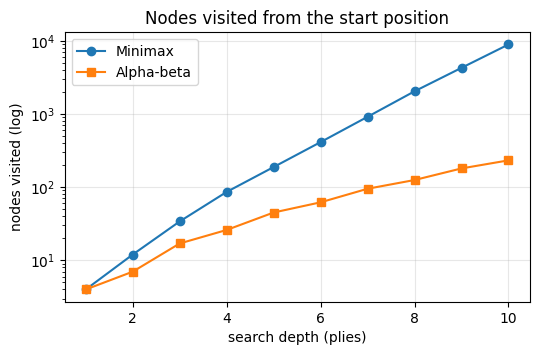

In [15]:
import time
rows = []
for d in range(1, 11):
    r = {"depth": d}
    for algo in ("minimax", "alphabeta"):
        m, v, n, secs = choose_move(START, d, algorithm=algo)
        r[algo] = (n, secs * 1000, move_name(START, m), v)
    rows.append(r)

print(f"{'depth':>5} {'minimax nodes':>14} {'ms':>8} {'alpha-beta nodes':>17} {'ms':>8} {'best move':>10} {'value':>6}")
for r in rows:
    (n1, t1, m1, v1), (n2, t2, m2, v2) = r["minimax"], r["alphabeta"]
    print(f"{r['depth']:>5} {n1:>14} {t1:>8.1f} {n2:>17} {t2:>8.1f} {m1:>10} {v1:>6g}")

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot([r["depth"] for r in rows], [r["minimax"][0] for r in rows], "o-", label="Minimax")
ax.plot([r["depth"] for r in rows], [r["alphabeta"][0] for r in rows], "s-", label="Alpha-beta")
ax.set_yscale("log"); ax.set_xlabel("search depth (plies)"); ax.set_ylabel("nodes visited (log)")
ax.set_title("Nodes visited from the start position"); ax.legend(); ax.grid(alpha=.3)
plt.show()

**Observations**

* Minimax nodes grow roughly geometrically with depth (effective branching factor ≈ 2). The board is tiny and many lines end early through captures, passes or repetition.
* Alpha-beta returns the same move and value at every depth while visiting far fewer nodes. The saving grows with depth because captures are searched first and often produce early cut-offs.
* From depth 3 the value is 997 = 1000 − 3: White, moving first, wins by force in 3 plies (H b3xc1, then it captures whatever Black has left). With White to move the start position is a forced win, so the computer is only beatable as White.

### 9.2 How the evaluation function affects play

Baseline for comparison: a material-only evaluation. For every reachable position with a real choice, we check whether a shallow search with each evaluation picks a move that a deep search rates as best.

In [16]:
def material_only(state):
    """Baseline evaluation used for comparison: material difference only."""
    t = eval_terms(state)
    return t["W"]["material"] - t["B"]["material"]


def self_play(depth_w, depth_b, eval_w=None, eval_b=None, start=START, algorithm="alphabeta"):
    """Computer vs computer, used only for the analysis section. Returns (result, moves)."""
    state, ply, history, moves = start, 0, Counter({start: 1}), []
    while not game_result(state, ply, history):
        w = state.turn == "W"
        move, *_ = choose_move(state, depth_w if w else depth_b, ply, history, algorithm,
                               eval_w if w else eval_b)
        moves.append(move_name(state, move))
        state = apply_move(state, move)
        ply += 1
        history[state] += 1
    return game_result(state, ply, history), moves


In [17]:
from collections import Counter

# every non-terminal position reachable within 6 plies that has a real choice
seen, frontier = set(), [START]
for _ in range(6):
    nxt = []
    for s in frontier:
        if s in seen or game_result(s, 0, Counter({s: 1})):
            continue
        seen.add(s)
        nxt += [apply_move(s, m) for m in search_moves(s)]
    frontier = nxt
positions = [s for s in seen if len(legal_moves(s)) > 1]

def deep_value(s, m, depth=9):
    c = apply_move(s, m)
    return alphabeta(c, depth, 1, Counter({s: 1, c: 1}))[0]

oracle = {}
for s in positions:
    vals = {m: deep_value(s, m) for m in legal_moves(s)}
    oracle[s] = (vals, max(vals.values()) if s.turn == "W" else min(vals.values()))

print(f"{len(positions)} positions; reference = best move by a depth-10 search")
print(f"{'depth':>5} {'full evaluation':>16} {'material only':>14}")
for d in (1, 2, 3):
    hits = {}
    for name, f in (("full", evaluate), ("material", material_only)):
        hits[name] = sum(oracle[s][0][choose_move(s, d, algorithm="alphabeta", eval_fn=f)[0]] == oracle[s][1]
                         for s in positions)
    print(f"{d:>5} {hits['full']:>10}/{len(positions)} {hits['material']:>10}/{len(positions)}")

96 positions; reference = best move by a depth-10 search
depth  full evaluation  material only
    1         72/96         69/96
    2         84/96         81/96
    3         86/96         86/96


**Observations**

* With a shallow search (depth 1–2), the full evaluation picks a game-theoretically best move more often than material alone. Mobility, threats and safety let it *see* a capture or a hanging piece one move before the material changes.
* As depth grows, both converge: the search itself finds the tactics, and the evaluation matters less. On a 3×3 board a depth of about 8 already reaches most game ends, which is why the default `DEPTH = 8` plays essentially perfectly.
* Limitation: the evaluation ignores **whose turn it is**. In the worked example, the static score called White's hanging knight a minus, while White to move actually wins material. The search fixes this, but a tempo term would help at depth 0–1.

## 10. Conclusion

* We modelled the 3×3 mini-chess from the assignment image with explicit, configurable interpretations of the pawn, the knight, the win condition, passing, draws and promotion.
* A hand-designed static evaluation (material 10/30, mobility, pawn advancement, threats, safety; no machine learning) was justified term by term and worked through on a sample state, giving a total of −8.
* The computer plays with Minimax (depth configurable, default 8). Alpha-beta pruning returns identical moves with far fewer nodes.
* A human plays through `input()` with full validation. `AUTO_DEMO` replays a scripted game so the notebook runs end to end.
* With these rules the side that moves first (White) has a forced win in 3 plies. The engine finds it, and punishes human mistakes, as the demo games show.